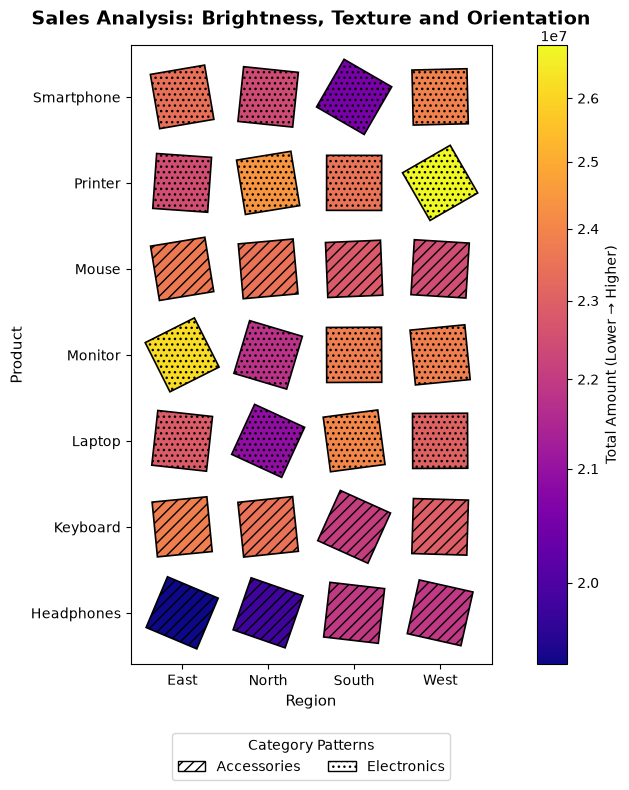

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Patch
from matplotlib import transforms, colors

# Load dataset
df = pd.read_csv("sales.csv")

# Aggregate data
data = df.groupby(
    ["Region", "Product", "Category"],
    as_index=False
).agg(
    TotalAmount=("TotalAmount", "sum"),
    Profit=("Profit", "sum")
)

regions = sorted(data["Region"].unique())
products = sorted(data["Product"].unique())
categories = sorted(data["Category"].unique())

x_pos = {r: i for i, r in enumerate(regions)}
y_pos = {p: i for i, p in enumerate(products)}

# Texture patterns
patterns = ["///", "...", "xxx", "+++", "ooo", "\\\\\\"]

pattern_map = {
    category: patterns[i % len(patterns)]
    for i, category in enumerate(categories)
}

# Vivid color gradient
cmap = plt.cm.plasma

norm = colors.PowerNorm(
    gamma=0.7,
    vmin=data["TotalAmount"].min(),
    vmax=data["TotalAmount"].max()
)

# Profit range for orientation
p_min = data["Profit"].min()
p_max = data["Profit"].max()

plt.rcParams["hatch.linewidth"] = 1.0

fig, ax = plt.subplots(figsize=(12, 8))

for _, row in data.iterrows():

    x = x_pos[row["Region"]]
    y = y_pos[row["Product"]]

    # COLOR + BRIGHTNESS: TotalAmount
    cell_color = cmap(norm(row["TotalAmount"]))

    # TEXTURE: Category
    pattern = pattern_map[row["Category"]]

    # ORIENTATION: Profit
    angle = (
        np.interp(row["Profit"], [p_min, p_max], [-30, 30])
        if p_max != p_min else 0
    )

    # Create colored square
    square = Rectangle(
        (x - 0.32, y - 0.32),
        0.64,
        0.64,
        facecolor=cell_color,
        edgecolor="black",
        linewidth=1.2,
        hatch=pattern,
        zorder=2
    )

    # Rotate square according to profit
    square.set_transform(
        transforms.Affine2D()
        .rotate_deg_around(x, y, angle)
        + ax.transData
    )

    ax.add_patch(square)

# Axis settings
ax.set_xticks(range(len(regions)))
ax.set_xticklabels(regions)

ax.set_yticks(range(len(products)))
ax.set_yticklabels(products)

ax.set_xlim(-0.6, len(regions) - 0.4)
ax.set_ylim(-0.6, len(products) - 0.4)
ax.set_aspect("equal")

ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Product", fontsize=11)

ax.set_title(
    "Sales Analysis: Brightness, Texture and Orientation",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Color scale
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.04,
    label="Total Amount (Lower → Higher)"
)

# Texture legend
handles = [
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch=pattern_map[category],
        label=category
    )
    for category in categories
]

ax.legend(
    handles=handles,
    title="Category Patterns",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=min(4, len(categories)),
    frameon=True
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()

# Save high-quality outputs
plt.savefig(
    "Experiment5_Visualization.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "Experiment5_Visualization.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

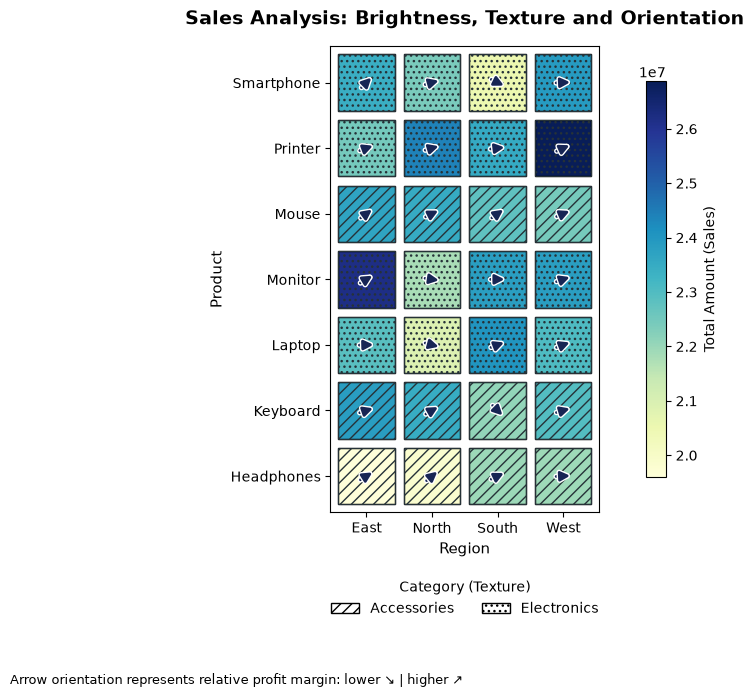

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Patch, FancyArrowPatch
from matplotlib import colors
import matplotlib.patheffects as pe

# Load dataset
df = pd.read_csv("sales.csv")

# Aggregate sales and profit
data = df.groupby(
    ["Region", "Product", "Category"],
    as_index=False
).agg(
    TotalAmount=("TotalAmount", "sum"),
    Profit=("Profit", "sum")
)

# Calculate profit margin
data["ProfitMargin"] = (
    data["Profit"] / data["TotalAmount"] * 100
)

regions = sorted(data["Region"].unique())
products = sorted(data["Product"].unique())
categories = sorted(data["Category"].unique())

x_pos = {r: i for i, r in enumerate(regions)}
y_pos = {p: i for i, p in enumerate(products)}

# Texture patterns for categories
patterns = ["///", "...", "xxx", "+++", "ooo", "\\\\\\"]

pattern_map = {
    c: patterns[i % len(patterns)]
    for i, c in enumerate(categories)
}

# Brightness and color represent sales
vmin = data["TotalAmount"].min()
vmax = data["TotalAmount"].max()

if vmin == vmax:
    vmax = vmin + 1

norm = colors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.cm.YlGnBu

# Orientation represents profit margin
pmin = data["ProfitMargin"].min()
pmax = data["ProfitMargin"].max()

fig, ax = plt.subplots(figsize=(12, 7))

for _, row in data.iterrows():

    x = x_pos[row["Region"]]
    y = y_pos[row["Product"]]

    # 1. BRIGHTNESS: TotalAmount
    face_color = cmap(norm(row["TotalAmount"]))

    ax.add_patch(
        Rectangle(
            (x - 0.43, y - 0.43),
            0.86, 0.86,
            facecolor=face_color,
            edgecolor="black",
            linewidth=1
        )
    )

    # 2. TEXTURE: Category
    ax.add_patch(
        Rectangle(
            (x - 0.43, y - 0.43),
            0.86, 0.86,
            facecolor="none",
            edgecolor="#263238",
            hatch=pattern_map[row["Category"]],
            linewidth=0.8
        )
    )

    # 3. ORIENTATION: Profit margin
    angle = (
        np.interp(row["ProfitMargin"], [pmin, pmax], [-45, 45])
        if pmax != pmin else 0
    )

    length = 0.30
    dx = length * np.cos(np.radians(angle))
    dy = length * np.sin(np.radians(angle))

    arrow = FancyArrowPatch(
        (x - dx / 2, y - dy / 2),
        (x + dx / 2, y + dy / 2),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=2,
        color="#172554",
        zorder=5
    )

    # White outline keeps arrows visible over dark cells
    arrow.set_path_effects([
        pe.Stroke(linewidth=4, foreground="white"),
        pe.Normal()
    ])

    ax.add_patch(arrow)

# Axis formatting
ax.set_xticks(range(len(regions)))
ax.set_xticklabels(regions)

ax.set_yticks(range(len(products)))
ax.set_yticklabels(products)

ax.set_xlim(-0.55, len(regions) - 0.45)
ax.set_ylim(-0.55, len(products) - 0.45)

ax.set_aspect("equal")
ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Product", fontsize=11)

ax.set_title(
    "Sales Analysis: Brightness, Texture and Orientation",
    fontsize=14,
    fontweight="bold",
    pad=16
)

# Color scale
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig.colorbar(
    sm,
    ax=ax,
    label="Total Amount (Sales)",
    pad=0.04,
    shrink=0.85
)

# Texture legend
handles = [
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch=pattern_map[c],
        label=c
    )
    for c in categories
]

ax.legend(
    handles=handles,
    title="Category (Texture)",
    bbox_to_anchor=(0.5, -0.12),
    loc="upper center",
    ncol=min(4, len(categories)),
    frameon=False
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.figtext(
    0.5, 0.015,
    "Arrow orientation represents relative profit margin: lower ↘ | higher ↗",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

# Save high-quality output for printing
plt.savefig(
    "Experiment5_Visualization.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "Experiment5_Visualization.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

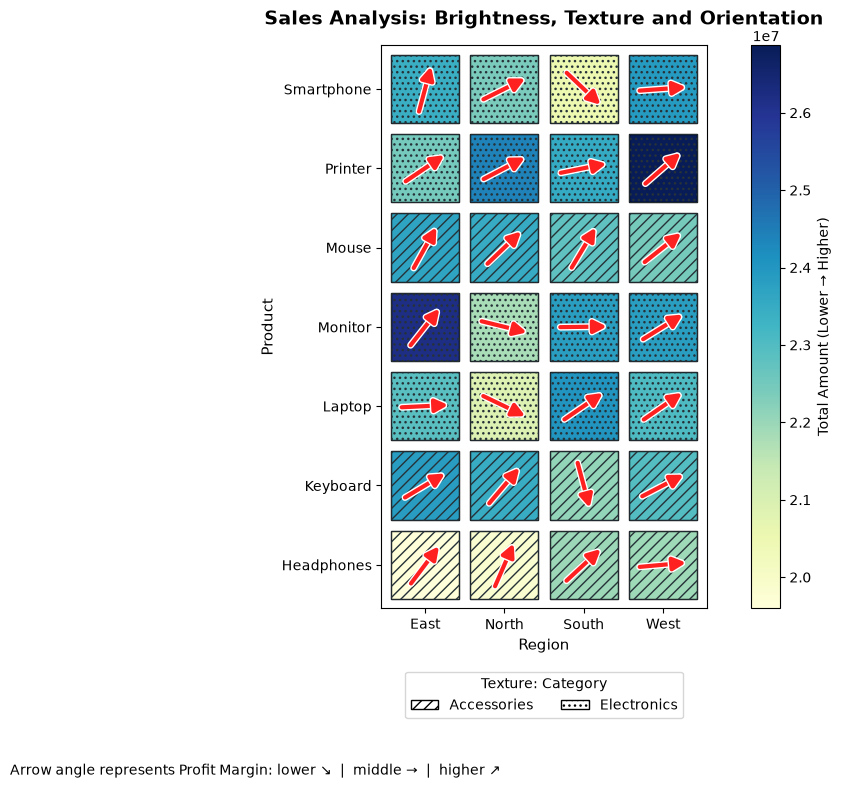

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Patch, FancyArrowPatch
from matplotlib import colors
import matplotlib.patheffects as pe

# Load dataset
df = pd.read_csv("sales.csv")

# Aggregate data
data = df.groupby(
    ["Region", "Product", "Category"],
    as_index=False
).agg(
    TotalAmount=("TotalAmount", "sum"),
    Profit=("Profit", "sum")
)

# Calculate profit margin
data["ProfitMargin"] = (
    data["Profit"] / data["TotalAmount"] * 100
)

regions = sorted(data["Region"].unique())
products = sorted(data["Product"].unique())
categories = sorted(data["Category"].unique())

x_pos = {r: i for i, r in enumerate(regions)}
y_pos = {p: i for i, p in enumerate(products)}

# Texture patterns
patterns = ["///", "...", "xxx", "+++", "ooo", "\\\\\\"]

pattern_map = {
    c: patterns[i % len(patterns)]
    for i, c in enumerate(categories)
}

# Brightness: TotalAmount
vmin = data["TotalAmount"].min()
vmax = data["TotalAmount"].max()

if vmin == vmax:
    vmax = vmin + 1

norm = colors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.cm.YlGnBu

# Orientation: Profit margin
pmin = data["ProfitMargin"].min()
pmax = data["ProfitMargin"].max()

fig, ax = plt.subplots(figsize=(12, 8))

for _, row in data.iterrows():

    x = x_pos[row["Region"]]
    y = y_pos[row["Product"]]

    # 1. BRIGHTNESS: Sales amount
    ax.add_patch(
        Rectangle(
            (x - 0.43, y - 0.43),
            0.86, 0.86,
            facecolor=cmap(norm(row["TotalAmount"])),
            edgecolor="black",
            linewidth=1,
            zorder=1
        )
    )

    # 2. TEXTURE: Category
    ax.add_patch(
        Rectangle(
            (x - 0.43, y - 0.43),
            0.86, 0.86,
            facecolor="none",
            edgecolor="#263238",
            hatch=pattern_map[row["Category"]],
            linewidth=0.6,
            zorder=2
        )
    )

    # 3. ORIENTATION: Profit margin
    if pmax != pmin:
        angle = np.interp(
            row["ProfitMargin"],
            [pmin, pmax],
            [-75, 75]
        )
    else:
        angle = 0

    # Long, prominent arrow
    length = 0.66

    dx = length * np.cos(np.radians(angle))
    dy = length * np.sin(np.radians(angle))

    arrow = FancyArrowPatch(
        (x - dx / 2, y - dy / 2),
        (x + dx / 2, y + dy / 2),
        arrowstyle="-|>",
        mutation_scale=19,
        linewidth=3,
        color="#ff2020",
        zorder=5
    )

    # White outline keeps arrows visible over every background
    arrow.set_path_effects([
        pe.Stroke(linewidth=5, foreground="white"),
        pe.Normal()
    ])

    ax.add_patch(arrow)

# Axis formatting
ax.set_xticks(range(len(regions)))
ax.set_xticklabels(regions)

ax.set_yticks(range(len(products)))
ax.set_yticklabels(products)

ax.set_xlim(-0.55, len(regions) - 0.45)
ax.set_ylim(-0.55, len(products) - 0.45)
ax.set_aspect("equal")

ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Product", fontsize=11)

ax.set_title(
    "Sales Analysis: Brightness, Texture and Orientation",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Brightness color scale
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig.colorbar(
    sm,
    ax=ax,
    label="Total Amount (Lower → Higher)",
    fraction=0.035,
    pad=0.04
)

# Texture legend
handles = [
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch=pattern_map[c],
        label=c
    )
    for c in categories
]

ax.legend(
    handles=handles,
    title="Texture: Category",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=min(4, len(categories)),
    frameon=True
)

fig.text(
    0.5, 0.025,
    "Arrow angle represents Profit Margin: "
    "lower ↘  |  middle →  |  higher ↗",
    ha="center",
    fontsize=10
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout(rect=[0, 0.07, 1, 1])

# Save print-quality outputs
plt.savefig(
    "Experiment5_Visualization.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "Experiment5_Visualization.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

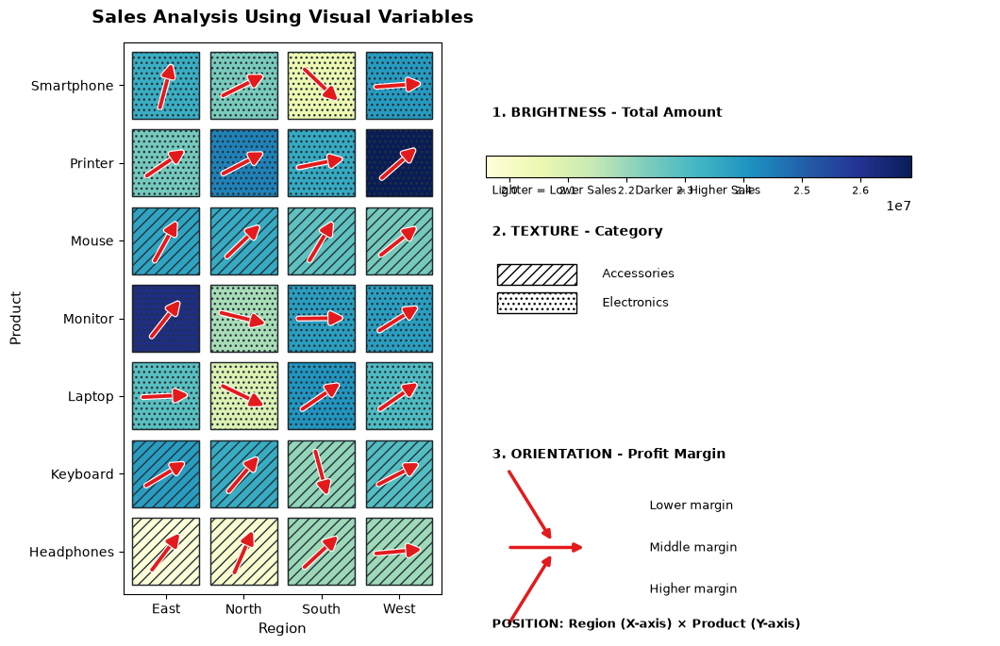

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, FancyArrowPatch
from matplotlib import colors
import matplotlib.patheffects as pe

# Load dataset
df = pd.read_csv("sales.csv")

# Aggregate sales and profit
data = df.groupby(
    ["Region", "Product", "Category"],
    as_index=False
).agg(
    TotalAmount=("TotalAmount", "sum"),
    Profit=("Profit", "sum")
)

# Calculate profit margin
data["ProfitMargin"] = (
    data["Profit"] / data["TotalAmount"] * 100
)

regions = sorted(data["Region"].unique())
products = sorted(data["Product"].unique())
categories = sorted(data["Category"].unique())

x_pos = {r: i for i, r in enumerate(regions)}
y_pos = {p: i for i, p in enumerate(products)}

# Texture patterns for categories
patterns = ["///", "...", "xxx", "+++", "ooo", "\\\\\\"]

pattern_map = {
    category: patterns[i % len(patterns)]
    for i, category in enumerate(categories)
}

# Colour scale for TotalAmount
vmin = data["TotalAmount"].min()
vmax = data["TotalAmount"].max()

if vmin == vmax:
    vmax = vmin + 1

norm = colors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.cm.YlGnBu

# Orientation scale for Profit Margin
pmin = data["ProfitMargin"].min()
pmax = data["ProfitMargin"].max()

# Create figure with a dedicated visual key
fig = plt.figure(figsize=(10.5, 7.5))
ax = fig.add_axes([0.05, 0.14, 0.43, 0.78])
key_ax = fig.add_axes([0.45, 0.08, 0.53, 0.84])
key_ax.set_axis_off()

# Draw the main visualization
for _, row in data.iterrows():

    x = x_pos[row["Region"]]
    y = y_pos[row["Product"]]

    # BRIGHTNESS: TotalAmount
    face_color = cmap(norm(row["TotalAmount"]))

    square = Rectangle(
        (x - 0.43, y - 0.43),
        0.86, 0.86,
        facecolor=face_color,
        edgecolor="black",
        linewidth=1
    )
    ax.add_patch(square)

    # TEXTURE: Category
    texture = Rectangle(
        (x - 0.43, y - 0.43),
        0.86, 0.86,
        facecolor="none",
        edgecolor="#263238",
        hatch=pattern_map[row["Category"]],
        linewidth=0.6
    )
    ax.add_patch(texture)

    # ORIENTATION: Profit Margin
    angle = (
        np.interp(row["ProfitMargin"], [pmin, pmax], [-75, 75])
        if pmax != pmin else 0
    )

    length = 0.66
    dx = length * np.cos(np.radians(angle))
    dy = length * np.sin(np.radians(angle))

    arrow = FancyArrowPatch(
        (x - dx / 2, y - dy / 2),
        (x + dx / 2, y + dy / 2),
        arrowstyle="-|>",
        mutation_scale=19,
        linewidth=2.8,
        color="#e31a1c",
        zorder=5
    )

    arrow.set_path_effects([
        pe.Stroke(linewidth=4.5, foreground="white"),
        pe.Normal()
    ])

    ax.add_patch(arrow)

# Main graph axes
ax.set_xticks(range(len(regions)))
ax.set_xticklabels(regions)
ax.set_yticks(range(len(products)))
ax.set_yticklabels(products)

ax.set_xlim(-0.55, len(regions) - 0.45)
ax.set_ylim(-0.55, len(products) - 0.45)
ax.set_aspect("equal")

ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Product", fontsize=11)

ax.set_title(
    "Sales Analysis Using Visual Variables",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# -------------------------------
# VISUAL KEY: BRIGHTNESS
# -------------------------------


key_ax.text(
    0.05, 0.875,
    "1. BRIGHTNESS - Total Amount",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

cax = fig.add_axes([0.47, 0.73, 0.43, 0.03])
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
cbar.ax.tick_params(labelsize=8)

key_ax.text(
    0.05, 0.745,
    "Lighter = Lower Sales     Darker = Higher Sales",
    fontsize=8.5,
    transform=key_ax.transAxes
)

# -------------------------------
# VISUAL KEY: TEXTURE
# -------------------------------
key_ax.text(
    0.05, 0.675,
    "2. TEXTURE - Category",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

start_y = 0.61
step = min(0.048, 0.22 / max(len(categories), 1))

for i, category in enumerate(categories):

    y = start_y - i * step

    sample = Rectangle(
        (0.06, y - 0.018),
        0.15, 0.035,
        facecolor="white",
        edgecolor="black",
        hatch=pattern_map[category],
        transform=key_ax.transAxes,
        clip_on=False
    )

    key_ax.add_patch(sample)

    key_ax.text(
        0.26, y,
        category,
        va="center",
        fontsize=9,
        transform=key_ax.transAxes
    )

# -------------------------------
# VISUAL KEY: ORIENTATION
# -------------------------------
key_ax.text(
    0.05, 0.30,
    "3. ORIENTATION - Profit Margin",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

examples = [
    (0.22, -55, "Lower margin"),
    (0.15, 0, "Middle margin"),
    (0.08, 55, "Higher margin")
]

for y, angle, label in examples:

    length = 0.15
    dx = length * np.cos(np.radians(angle))
    dy = length * np.sin(np.radians(angle))

    arrow = FancyArrowPatch(
        (0.08, y - dy / 2),
        (0.08 + dx, y + dy / 2),
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=2.5,
        color="#e31a1c",
        transform=key_ax.transAxes,
        clip_on=False
    )

    key_ax.add_patch(arrow)

    key_ax.text(
        0.35, y,
        label,
        va="center",
        fontsize=9,
        transform=key_ax.transAxes
    )

# Position explanation
key_ax.text(
    0.05, 0.015,
    "POSITION: Region (X-axis) × Product (Y-axis)",
    fontsize=9,
    fontweight="bold",
    transform=key_ax.transAxes
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Save print-quality outputs
fig.savefig(
    "Experiment5_Visualization.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    "Experiment5_Visualization.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

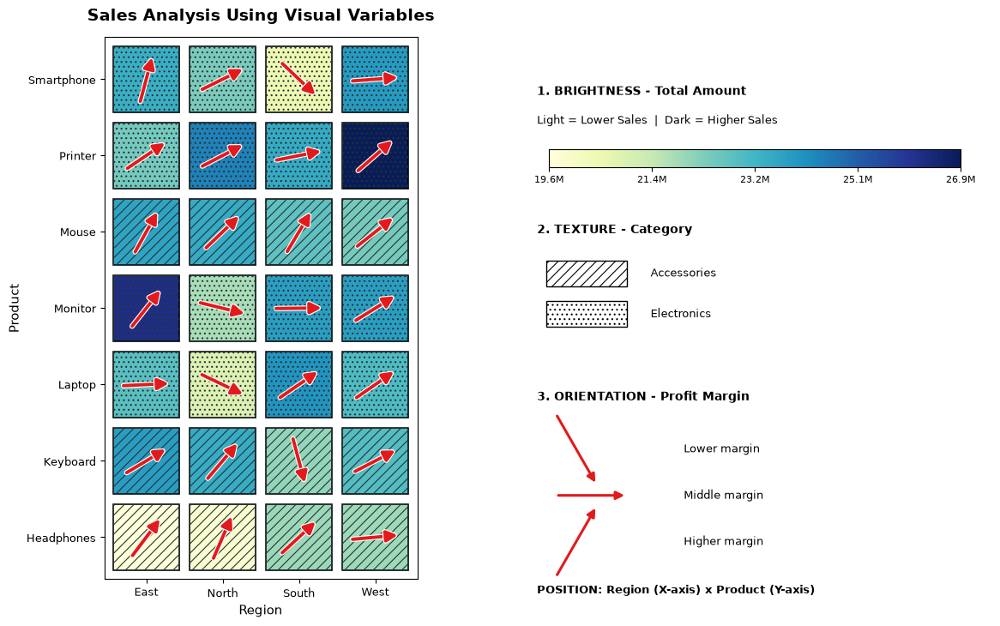

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, FancyArrowPatch
from matplotlib import colors
import matplotlib.patheffects as pe

# Load dataset
df = pd.read_csv("sales.csv")

# Aggregate sales and profit
data = df.groupby(
    ["Region", "Product", "Category"],
    as_index=False
).agg(
    TotalAmount=("TotalAmount", "sum"),
    Profit=("Profit", "sum")
)

# Calculate profit margin
data["ProfitMargin"] = (
    data["Profit"] / data["TotalAmount"] * 100
)

regions = sorted(data["Region"].unique())
products = sorted(data["Product"].unique())
categories = sorted(data["Category"].unique())

x_pos = {r: i for i, r in enumerate(regions)}
y_pos = {p: i for i, p in enumerate(products)}

# Texture patterns for categories
patterns = ["///", "...", "xxx", "+++", "ooo", "\\\\\\"]

pattern_map = {
    category: patterns[i % len(patterns)]
    for i, category in enumerate(categories)
}

# Brightness and color scale
vmin = data["TotalAmount"].min()
vmax = data["TotalAmount"].max()

if vmin == vmax:
    vmax = vmin + 1

norm = colors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.cm.YlGnBu

# Orientation scale
pmin = data["ProfitMargin"].min()
pmax = data["ProfitMargin"].max()

plt.rcParams["hatch.linewidth"] = 0.8

# Figure and axes
fig = plt.figure(figsize=(12, 8))

ax = fig.add_axes([0.06, 0.13, 0.40, 0.79])
key_ax = fig.add_axes([0.51, 0.08, 0.46, 0.84])
key_ax.set_axis_off()

# ==========================================
# MAIN GRAPH
# ==========================================

for _, row in data.iterrows():

    x = x_pos[row["Region"]]
    y = y_pos[row["Product"]]

    # 1. BRIGHTNESS: TotalAmount
    face_color = cmap(norm(row["TotalAmount"]))

    square = Rectangle(
        (x - 0.43, y - 0.43),
        0.86,
        0.86,
        facecolor=face_color,
        edgecolor="black",
        linewidth=1.1
    )
    ax.add_patch(square)

    # 2. TEXTURE: Category
    texture = Rectangle(
        (x - 0.43, y - 0.43),
        0.86,
        0.86,
        facecolor="none",
        edgecolor="#263238",
        hatch=pattern_map[row["Category"]],
        linewidth=0.6
    )
    ax.add_patch(texture)

    # 3. ORIENTATION: Profit Margin
    if pmax != pmin:
        angle = np.interp(
            row["ProfitMargin"],
            [pmin, pmax],
            [-75, 75]
        )
    else:
        angle = 0

    length = 0.66

    dx = length * np.cos(np.radians(angle))
    dy = length * np.sin(np.radians(angle))

    arrow = FancyArrowPatch(
        (x - dx / 2, y - dy / 2),
        (x + dx / 2, y + dy / 2),
        arrowstyle="-|>",
        mutation_scale=19,
        linewidth=2.8,
        color="#e31a1c",
        zorder=5
    )

    # White outline keeps arrows visible on every color
    arrow.set_path_effects([
        pe.Stroke(linewidth=4.5, foreground="white"),
        pe.Normal()
    ])

    ax.add_patch(arrow)

# Format main axes
ax.set_xticks(range(len(regions)))
ax.set_xticklabels(regions)

ax.set_yticks(range(len(products)))
ax.set_yticklabels(products)

ax.set_xlim(-0.55, len(regions) - 0.45)
ax.set_ylim(-0.55, len(products) - 0.45)
ax.set_aspect("equal")

ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Product", fontsize=11)

ax.set_title(
    "Sales Analysis Using Visual Variables",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.tick_params(axis="both", labelsize=9)

# ==========================================
# VISUAL KEY
# ==========================================



# ------------------------------------------
# 1. BRIGHTNESS
# ------------------------------------------

key_ax.text(
    0.04, 0.90,
    "1. BRIGHTNESS - Total Amount",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

key_ax.text(
    0.04, 0.85,
    "Light = Lower Sales  |  Dark = Higher Sales",
    fontsize=9,
    transform=key_ax.transAxes
)

# Color bar placed independently to avoid overlaps
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cax = fig.add_axes([0.54, 0.73, 0.40, 0.027])

cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")

# Use readable million-scale labels where appropriate
ticks = np.linspace(vmin, vmax, 5)
cbar.set_ticks(ticks)

if vmax >= 1_000_000:
    cbar.set_ticklabels([f"{v / 1_000_000:.1f}M" for v in ticks])
else:
    cbar.set_ticklabels([f"{v:,.0f}" for v in ticks])

cbar.ax.tick_params(labelsize=8, pad=3)

# ------------------------------------------
# 2. TEXTURE
# ------------------------------------------

key_ax.text(
    0.04, 0.66,
    "2. TEXTURE - Category",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

start_y = 0.59
step = min(0.07, 0.18 / max(len(categories), 1))

for i, category in enumerate(categories):

    y = start_y - i * step

    sample = Rectangle(
        (0.06, y - 0.022),
        0.17,
        0.044,
        facecolor="white",
        edgecolor="black",
        hatch=pattern_map[category],
        transform=key_ax.transAxes,
        clip_on=False
    )

    key_ax.add_patch(sample)

    key_ax.text(
        0.28,
        y,
        category,
        va="center",
        fontsize=9,
        transform=key_ax.transAxes
    )

# ------------------------------------------
# 3. ORIENTATION
# ------------------------------------------

key_ax.text(
    0.04, 0.37,
    "3. ORIENTATION - Profit Margin",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

examples = [
    (0.285, -55, "Lower margin"),
    (0.205, 0, "Middle margin"),
    (0.125, 55, "Higher margin")
]

for y, angle, label in examples:

    length = 0.15

    dx = length * np.cos(np.radians(angle))
    dy = length * np.sin(np.radians(angle))

    arrow = FancyArrowPatch(
        (0.08, y - dy / 2),
        (0.08 + dx, y + dy / 2),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=2.2,
        color="#e31a1c",
        transform=key_ax.transAxes,
        clip_on=False
    )

    key_ax.add_patch(arrow)

    key_ax.text(
        0.35,
        y,
        label,
        va="center",
        fontsize=9,
        transform=key_ax.transAxes
    )

# ------------------------------------------
# POSITION
# ------------------------------------------

key_ax.text(
    0.04, 0.035,
    "POSITION: Region (X-axis) x Product (Y-axis)",
    fontsize=9,
    fontweight="bold",
    transform=key_ax.transAxes
)

# White backgrounds
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Save print-quality outputs
fig.savefig(
    "Experiment5_Visualization.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    "Experiment5_Visualization.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

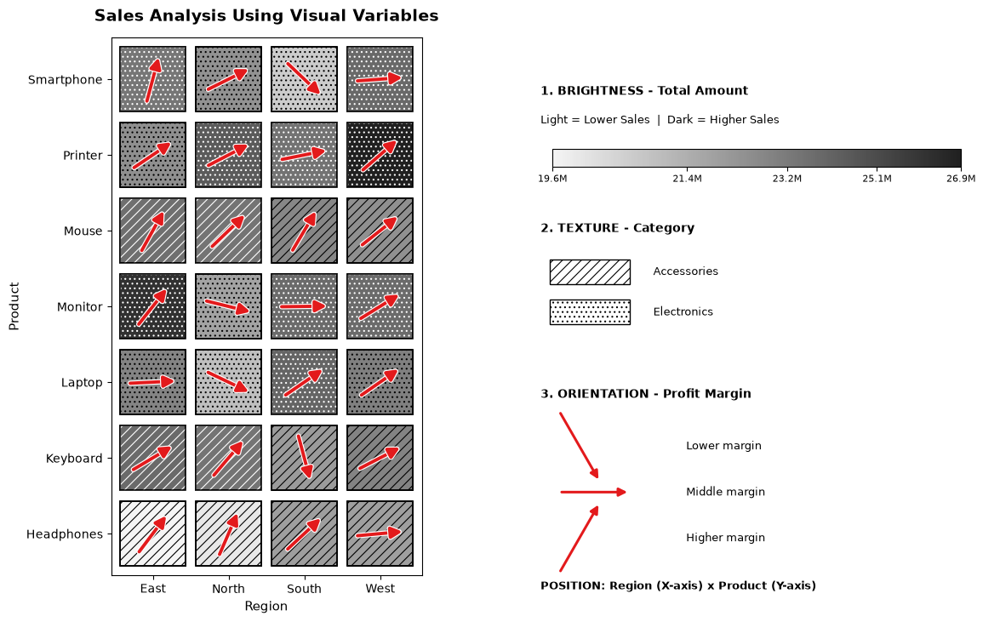

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, FancyArrowPatch, Patch
from matplotlib import colors
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patheffects as pe

# Load dataset
df = pd.read_csv("sales.csv")

# Aggregate data
data = df.groupby(
    ["Region", "Product", "Category"],
    as_index=False
).agg(
    TotalAmount=("TotalAmount", "sum"),
    Profit=("Profit", "sum")
)

# Calculate profit margin
data["ProfitMargin"] = (
    data["Profit"] / data["TotalAmount"] * 100
)

regions = sorted(data["Region"].unique())
products = sorted(data["Product"].unique())
categories = sorted(data["Category"].unique())

x_pos = {r: i for i, r in enumerate(regions)}
y_pos = {p: i for i, p in enumerate(products)}

# Texture patterns
patterns = ["///", "...", "xxx", "+++", "ooo", "\\\\\\"]

pattern_map = {
    category: patterns[i % len(patterns)]
    for i, category in enumerate(categories)
}

# BRIGHTNESS: Monochrome light-to-dark gradient
brightness_cmap = LinearSegmentedColormap.from_list(
    "brightness",
    ["#F5F5F5", "#202020"]
)

vmin = data["TotalAmount"].min()
vmax = data["TotalAmount"].max()

if vmin == vmax:
    vmax = vmin + 1

norm = colors.PowerNorm(
    gamma=0.8,
    vmin=vmin,
    vmax=vmax
)

# ORIENTATION: Profit margin
pmin = data["ProfitMargin"].min()
pmax = data["ProfitMargin"].max()

plt.rcParams["hatch.linewidth"] = 0.8

# Figure layout
fig = plt.figure(figsize=(12, 8))

ax = fig.add_axes([0.06, 0.13, 0.40, 0.79])
key_ax = fig.add_axes([0.51, 0.08, 0.46, 0.84])
key_ax.set_axis_off()

# ==========================================
# MAIN GRAPH
# ==========================================

for _, row in data.iterrows():

    x = x_pos[row["Region"]]
    y = y_pos[row["Product"]]

    # 1. BRIGHTNESS: TotalAmount
    value = norm(row["TotalAmount"])
    face_color = brightness_cmap(value)

    square = Rectangle(
        (x - 0.43, y - 0.43),
        0.86,
        0.86,
        facecolor=face_color,
        edgecolor="black",
        linewidth=1.1
    )
    ax.add_patch(square)

    # 2. TEXTURE: Category
    # Choose a contrasting hatch color for readability
    hatch_color = "white" if value > 0.55 else "black"

    texture = Rectangle(
        (x - 0.43, y - 0.43),
        0.86,
        0.86,
        facecolor="none",
        edgecolor=hatch_color,
        hatch=pattern_map[row["Category"]],
        linewidth=0.6
    )
    ax.add_patch(texture)

    # Add a separate black border around each cell
    border = Rectangle(
        (x - 0.43, y - 0.43),
        0.86,
        0.86,
        facecolor="none",
        edgecolor="black",
        linewidth=1.1
    )
    ax.add_patch(border)

    # 3. ORIENTATION: Profit margin
    angle = (
        np.interp(
            row["ProfitMargin"],
            [pmin, pmax],
            [-75, 75]
        )
        if pmax != pmin else 0
    )

    length = 0.66
    dx = length * np.cos(np.radians(angle))
    dy = length * np.sin(np.radians(angle))

    arrow = FancyArrowPatch(
        (x - dx / 2, y - dy / 2),
        (x + dx / 2, y + dy / 2),
        arrowstyle="-|>",
        mutation_scale=19,
        linewidth=2.8,
        color="#E31A1C",
        zorder=5
    )

    # White outline makes arrows visible over light and dark cells
    arrow.set_path_effects([
        pe.Stroke(linewidth=4.5, foreground="white"),
        pe.Normal()
    ])

    ax.add_patch(arrow)

# Main graph formatting
ax.set_xticks(range(len(regions)))
ax.set_xticklabels(regions)

ax.set_yticks(range(len(products)))
ax.set_yticklabels(products)

ax.set_xlim(-0.55, len(regions) - 0.45)
ax.set_ylim(-0.55, len(products) - 0.45)
ax.set_aspect("equal")

ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Product", fontsize=11)

ax.set_title(
    "Sales Analysis Using Visual Variables",
    fontsize=14,
    fontweight="bold",
    pad=14
)

# ==========================================
# VISUAL KEY
# ==========================================


# ------------------------------------------
# 1. BRIGHTNESS
# ------------------------------------------

key_ax.text(
    0.04, 0.90,
    "1. BRIGHTNESS - Total Amount",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

key_ax.text(
    0.04, 0.85,
    "Light = Lower Sales  |  Dark = Higher Sales",
    fontsize=9,
    transform=key_ax.transAxes
)

# Monochrome brightness scale
sm = plt.cm.ScalarMappable(norm=norm, cmap=brightness_cmap)
sm.set_array([])

cax = fig.add_axes([0.54, 0.73, 0.40, 0.027])
cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")

ticks = np.linspace(vmin, vmax, 5)
cbar.set_ticks(ticks)

if vmax >= 1_000_000:
    cbar.set_ticklabels([f"{v / 1_000_000:.1f}M" for v in ticks])
else:
    cbar.set_ticklabels([f"{v:,.0f}" for v in ticks])

cbar.ax.tick_params(labelsize=8, pad=3)

# ------------------------------------------
# 2. TEXTURE
# ------------------------------------------

key_ax.text(
    0.04, 0.66,
    "2. TEXTURE - Category",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

start_y = 0.59
step = min(0.07, 0.18 / max(len(categories), 1))

for i, category in enumerate(categories):

    y = start_y - i * step

    sample = Rectangle(
        (0.06, y - 0.022),
        0.17,
        0.044,
        facecolor="white",
        edgecolor="black",
        hatch=pattern_map[category],
        transform=key_ax.transAxes,
        clip_on=False
    )

    key_ax.add_patch(sample)

    key_ax.text(
        0.28,
        y,
        category,
        va="center",
        fontsize=9,
        transform=key_ax.transAxes
    )

# ------------------------------------------
# 3. ORIENTATION
# ------------------------------------------

key_ax.text(
    0.04, 0.37,
    "3. ORIENTATION - Profit Margin",
    fontsize=10,
    fontweight="bold",
    transform=key_ax.transAxes
)

examples = [
    (0.285, -55, "Lower margin"),
    (0.205, 0, "Middle margin"),
    (0.125, 55, "Higher margin")
]

for y, angle, label in examples:

    length = 0.15
    dx = length * np.cos(np.radians(angle))
    dy = length * np.sin(np.radians(angle))

    arrow = FancyArrowPatch(
        (0.08, y - dy / 2),
        (0.08 + dx, y + dy / 2),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=2.2,
        color="#E31A1C",
        transform=key_ax.transAxes,
        clip_on=False
    )

    key_ax.add_patch(arrow)

    key_ax.text(
        0.35,
        y,
        label,
        va="center",
        fontsize=9,
        transform=key_ax.transAxes
    )

# Position explanation
key_ax.text(
    0.04, 0.035,
    "POSITION: Region (X-axis) x Product (Y-axis)",
    fontsize=9,
    fontweight="bold",
    transform=key_ax.transAxes
)

# White background
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Save print-quality outputs
fig.savefig(
    "Experiment5_Visualization.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    "Experiment5_Visualization.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

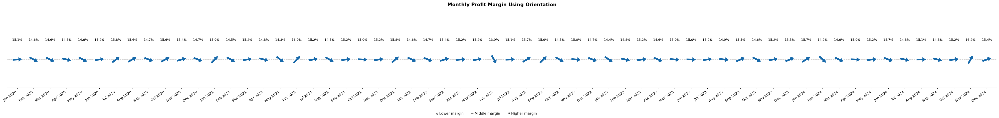

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.path import Path
from matplotlib.markers import MarkerStyle
from matplotlib.transforms import Affine2D

# Load dataset
df = pd.read_csv("sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Aggregate data month-wise
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

monthly = df.groupby("Month", as_index=False).agg(
    TotalAmount=("TotalAmount", "sum"),
    Profit=("Profit", "sum")
)

# Calculate profit margin
monthly["ProfitMargin"] = (
    monthly["Profit"] / monthly["TotalAmount"] * 100
)

# Map profit margin to angles
low = monthly["ProfitMargin"].min()
high = monthly["ProfitMargin"].max()

if low == high:
    monthly["Angle"] = 0
else:
    monthly["Angle"] = np.interp(
        monthly["ProfitMargin"],
        [low, high],
        [-60, 60]
    )

# Create a right-facing arrow shape
vertices = [
    (-1, -0.22), (0.2, -0.22), (0.2, -0.55),
    (1, 0), (0.2, 0.55), (0.2, 0.22),
    (-1, 0.22), (-1, -0.22)
]

codes = [
    Path.MOVETO, Path.LINETO, Path.LINETO,
    Path.LINETO, Path.LINETO, Path.LINETO,
    Path.LINETO, Path.CLOSEPOLY
]

arrow_path = Path(vertices, codes)

# Plot
fig, ax = plt.subplots(
    figsize=(max(11, len(monthly) * 0.85), 5)
)

for i, row in monthly.reset_index(drop=True).iterrows():

    marker = MarkerStyle(
        arrow_path,
        transform=Affine2D().rotate_deg(row["Angle"])
    )

    # Same color and size for every arrow
    ax.scatter(
        i, 0,
        marker=marker,
        s=800,
        color="#1769AA",
        edgecolors="white",
        linewidths=1.2,
        zorder=3
    )

    # Display the actual monthly profit margin
    ax.text(
        i, 0.25,
        f'{row["ProfitMargin"]:.1f}%',
        ha="center",
        va="bottom",
        fontsize=9
    )

# Format axes
ax.set_xticks(range(len(monthly)))
ax.set_xticklabels(
    monthly["Month"].dt.strftime("%b %Y"),
    rotation=35,
    ha="right"
)

ax.set_xlim(-0.6, len(monthly) - 0.4)
ax.set_ylim(-0.4, 0.65)
ax.set_yticks([])
ax.set_ylabel("")

ax.axhline(0, color="lightgray", linewidth=1, linestyle="--", zorder=0)

ax.set_title(
    "Monthly Profit Margin Using Orientation",
    fontsize=14,
    fontweight="bold",
    pad=20
)

# Explain the orientation encoding
fig.text(
    0.5, 0.025,
    "↘ Lower margin       → Middle margin       ↗ Higher margin",
    ha="center",
    fontsize=10
)

ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.subplots_adjust(bottom=0.24, top=0.84)
plt.savefig(
    "Experiment5_Orientation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

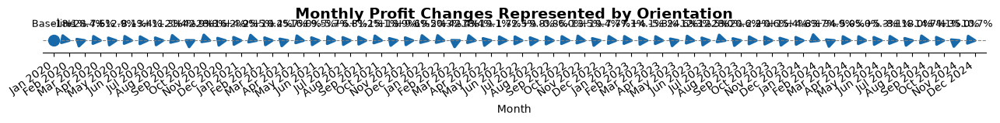

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyArrowPatch
import matplotlib.patheffects as pe

# Load dataset
df = pd.read_csv("sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Calculate monthly profit
df["Month"] = df["Date"].dt.to_period("M")

monthly = (
    df.groupby("Month")["Profit"]
    .sum()
    .reset_index()
)

monthly["Month"] = monthly["Month"].dt.to_timestamp()

# Calculate month-to-month percentage change in profit
monthly["Change"] = monthly["Profit"].pct_change() * 100
monthly["Change"] = monthly["Change"].replace(
    [np.inf, -np.inf], np.nan
)

# Map percentage change to arrow angles
# Limit the range to keep extreme changes readable
monthly["Angle"] = (
    monthly["Change"].clip(-100, 100).fillna(0) / 100 * 60
)

fig, ax = plt.subplots(figsize=(13, 4))

for i, row in monthly.iterrows():

    # First month is the baseline
    if i == 0:
        ax.scatter(i, 0, s=100, color="#1769AA", zorder=3)
        label = "Baseline"
    else:
        angle = np.radians(row["Angle"])
        length = 0.68

        dx = length * np.cos(angle)
        dy = length * np.sin(angle)

        arrow = FancyArrowPatch(
            (i - dx / 2, -dy / 2),
            (i + dx / 2, dy / 2),
            arrowstyle="-|>",
            mutation_scale=17,
            linewidth=2.5,
            color="#1769AA"
        )

        arrow.set_path_effects([
            pe.Stroke(linewidth=4, foreground="white"),
            pe.Normal()
        ])

        ax.add_patch(arrow)
        label = f"{row['Change']:+.1f}%"

    # Display monthly change
    ax.text(
        i, 0.73,
        label,
        ha="center",
        va="bottom",
        fontsize=9
    )

# Formatting
ax.set_xticks(range(len(monthly)))
ax.set_xticklabels(
    monthly["Month"].dt.strftime("%b %Y"),
    rotation=35,
    ha="right"
)

ax.set_xlim(-0.7, len(monthly) - 0.3)
ax.set_ylim(-0.8, 1.0)
ax.set_aspect("equal", adjustable="box")

ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")

ax.set_yticks([])
ax.set_ylabel("")
ax.set_xlabel("Month")

ax.set_title(
    "Monthly Profit Changes Represented by Orientation",
    fontsize=14,
    fontweight="bold"
)

ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "Experiment5_Orientation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Load dataset
df = pd.read_csv("sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Extract month
df["Month"] = df["Date"].dt.to_period("M")

# Calculate monthly sales by region
monthly = df.groupby(
    ["Month", "Region"]
)["TotalAmount"].sum().unstack(fill_value=0)

regions = sorted(df["Region"].unique())
monthly = monthly.reindex(columns=regions, fill_value=0)

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Initial values
values = monthly.iloc[0].values

bars = ax.barh(
    regions,
    values,
    color=["#4472C4", "#ED7D31", "#70AD47", "#A5A5A5"],
    edgecolor="black"
)

# Fixed axis scale for fair comparison
max_sales = monthly.values.max()
ax.set_xlim(0, max_sales * 1.2)

ax.set_xlabel("Total Sales")
ax.set_ylabel("Region")

# Display values on bars
labels = [
    ax.text(
        bar.get_width() + max_sales * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():,.0f}",
        va="center",
        fontsize=9
    )
    for bar in bars
]

def update(frame):

    values = monthly.iloc[frame].values

    for bar, value, label in zip(bars, values, labels):
        bar.set_width(value)
        label.set_text(f"{value:,.0f}")
        label.set_position((
            value + max_sales * 0.01,
            bar.get_y() + bar.get_height() / 2
        ))

    month = monthly.index[frame].strftime("%B %Y")

    ax.set_title(
        f"Monthly Sales by Region — {month}",
        fontsize=14,
        fontweight="bold"
    )

    return list(bars) + labels

# Animate month by month
anim = FuncAnimation(
    fig,
    update,
    frames=len(monthly),
    interval=800,
    repeat=True,
    blit=False
)

plt.tight_layout()
plt.close(fig)

# Display animation in Jupyter Notebook
display(HTML(anim.to_jshtml()))

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import numpy as np

# Load dataset
df = pd.read_csv("sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Calculate total sales for each date
daily = (
    df.groupby("Date", as_index=False)["TotalAmount"]
    .sum()
    .sort_values("Date")
    .reset_index(drop=True)
)

# Create figure
fig, ax = plt.subplots(figsize=(11, 6))

# Display complete date range
ax.set_xlim(daily["Date"].min(), daily["Date"].max())
ax.set_ylim(0, daily["TotalAmount"].max() * 1.15)

ax.set_xlabel("Date")
ax.set_ylabel("Total Sales")
ax.set_title("Motion Visualization: Date vs Total Sales",
             fontsize=14, fontweight="bold")

# Format dates
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Animated line and moving marker
line, = ax.plot(
    [], [],
    color="steelblue",
    linewidth=2,
    label="Daily Total Sales"
)

point, = ax.plot(
    [], [],
    marker="o",
    color="crimson",
    markersize=8
)

date_label = ax.text(
    0.03, 0.92, "",
    transform=ax.transAxes,
    fontsize=10
)

ax.grid(alpha=0.25)
ax.legend(loc="upper right")

# Limit frames for smooth rendering
frames = np.linspace(
    1, len(daily),
    min(100, len(daily)),
    dtype=int
)
frames = np.unique(frames)


def update(frame):
    current = daily.iloc[:frame]

    # Reveal sales trend progressively
    line.set_data(
        current["Date"],
        current["TotalAmount"]
    )

    # Move marker to the latest date
    point.set_data(
        [daily["Date"].iloc[frame - 1]],
        [daily["TotalAmount"].iloc[frame - 1]]
    )

    date_label.set_text(
        "Date: " + daily["Date"].iloc[frame - 1].strftime("%d %b %Y")
    )

    return line, point, date_label


# Create animation
anim = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=150,
    repeat=True,
    blit=False
)

plt.tight_layout()
plt.close(fig)

# Display animation in Jupyter Notebook
display(HTML(anim.to_jshtml(fps=10)))

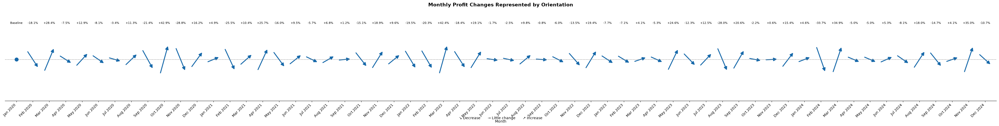

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyArrowPatch

# Load dataset
df = pd.read_csv("sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Calculate monthly profit
df["Month"] = df["Date"].dt.to_period("M")

monthly = (
    df.groupby("Month")["Profit"]
    .sum()
    .reset_index()
)

monthly["Month"] = monthly["Month"].dt.to_timestamp()

# Calculate month-to-month profit change (%)
monthly["Change"] = monthly["Profit"].pct_change(fill_method=None) * 100
monthly["Change"] = monthly["Change"].replace(
    [np.inf, -np.inf], np.nan
)

# Map changes to arrow angles
# Positive = upward, negative = downward
monthly["Angle"] = np.degrees(
    np.arctan(monthly["Change"].fillna(0) / 35)
).clip(-60, 60)

# Create plot
n = len(monthly)
fig, ax = plt.subplots(figsize=(max(12, n * 0.65), 5))

for i, row in monthly.iterrows():

    if pd.isna(row["Change"]):
        # First month is the baseline
        ax.scatter(i, 0, s=100, color="#1769AA", zorder=3)
        label = "Baseline"
    else:
        angle = np.radians(row["Angle"])
        length = 0.75

        dx = length * np.cos(angle)
        dy = length * np.sin(angle)

        arrow = FancyArrowPatch(
            (i - dx / 2, -dy / 2),
            (i + dx / 2, dy / 2),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=2.5,
            color="#1769AA"
        )

        ax.add_patch(arrow)
        label = f"{row['Change']:+.1f}%"

    # Show monthly change above each arrow
    ax.text(
        i, 0.72, label,
        ha="center",
        va="bottom",
        fontsize=8
    )

# Format graph
ax.set_xticks(range(n))
ax.set_xticklabels(
    monthly["Month"].dt.strftime("%b %Y"),
    rotation=45,
    ha="right"
)

ax.set_xlim(-0.7, n - 0.3)
ax.set_ylim(-0.85, 1.05)
ax.set_yticks([])

ax.set_xlabel("Month")
ax.set_title(
    "Monthly Profit Changes Represented by Orientation",
    fontsize=14,
    fontweight="bold"
)

ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")

ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

# Orientation guide
ax.text(
    0.5, -0.20,
    "↘ Decrease       → Little change       ↗ Increase",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

plt.tight_layout()
plt.savefig(
    "Experiment5_Orientation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

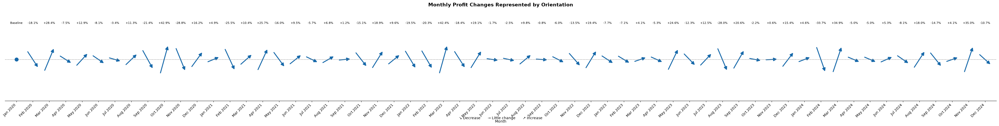

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyArrowPatch

# Load dataset
df = pd.read_csv("sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Calculate monthly profit
df["Month"] = df["Date"].dt.to_period("M")

monthly = (
    df.groupby("Month")["Profit"]
    .sum()
    .reset_index()
)

monthly["Month"] = monthly["Month"].dt.to_timestamp()

# Calculate month-to-month profit change (%)
monthly["Change"] = monthly["Profit"].pct_change(fill_method=None) * 100
monthly["Change"] = monthly["Change"].replace(
    [np.inf, -np.inf], np.nan
)

# Map changes to arrow angles
# Positive = upward, negative = downward
monthly["Angle"] = np.degrees(
    np.arctan(monthly["Change"].fillna(0) / 35)
).clip(-60, 60)

# Create plot
n = len(monthly)
fig, ax = plt.subplots(figsize=(max(12, n * 0.65), 5))

for i, row in monthly.iterrows():

    if pd.isna(row["Change"]):
        # First month is the baseline
        ax.scatter(i, 0, s=100, color="#1769AA", zorder=3)
        label = "Baseline"
    else:
        angle = np.radians(row["Angle"])
        length = 0.75

        dx = length * np.cos(angle)
        dy = length * np.sin(angle)

        arrow = FancyArrowPatch(
            (i - dx / 2, -dy / 2),
            (i + dx / 2, dy / 2),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=2.5,
            color="#1769AA"
        )

        ax.add_patch(arrow)
        label = f"{row['Change']:+.1f}%"

    # Show monthly change above each arrow
    ax.text(
        i, 0.72, label,
        ha="center",
        va="bottom",
        fontsize=8
    )

# Format graph
ax.set_xticks(range(n))
ax.set_xticklabels(
    monthly["Month"].dt.strftime("%b %Y"),
    rotation=45,
    ha="right"
)

ax.set_xlim(-0.7, n - 0.3)
ax.set_ylim(-0.85, 1.05)
ax.set_yticks([])

ax.set_xlabel("Month")
ax.set_title(
    "Monthly Profit Changes Represented by Orientation",
    fontsize=14,
    fontweight="bold"
)

ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")

ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

# Orientation guide
ax.text(
    0.5, -0.20,
    "↘ Decrease       → Little change       ↗ Increase",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

plt.tight_layout()
plt.savefig(
    "Experiment5_Orientation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

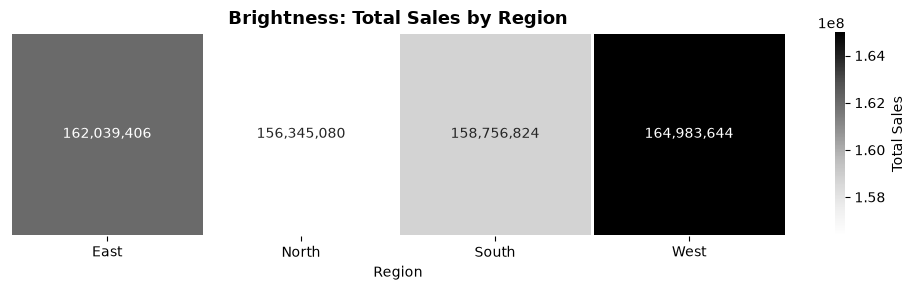

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Load dataset
df = pd.read_csv("sales.csv")

# Calculate total sales by region
sales = df.groupby("Region")["TotalAmount"].sum()

# Create heatmap
fig, ax = plt.subplots(figsize=(10, 3))

sns.heatmap(
    sales.to_frame().T,
    annot=True,
    fmt=",.0f",
    cmap="Greys",
    linewidths=2,
    linecolor="white",
    cbar_kws={"label": "Total Sales"},
    ax=ax
)

# Display full numbers on the color scale
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)
cbar.update_ticks()

ax.set_title(
    "Brightness: Total Sales by Region",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Region")
ax.set_ylabel("")
ax.set_yticks([])

plt.tight_layout()
plt.savefig(
    "Experiment5_Brightness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

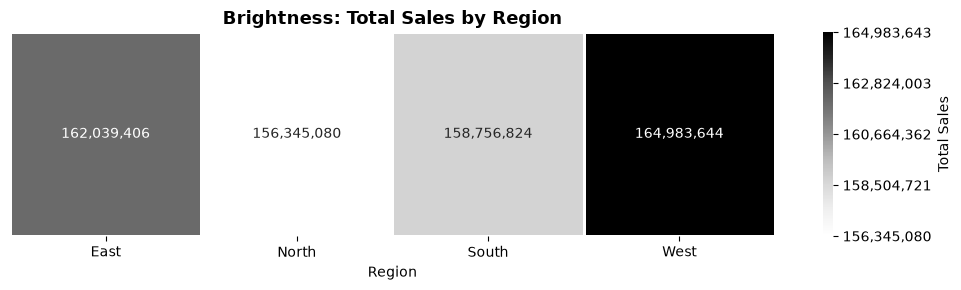

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load dataset
df = pd.read_csv("sales.csv")

# Calculate total sales by region
sales = df.groupby("Region")["TotalAmount"].sum()

# Create heatmap
fig, ax = plt.subplots(figsize=(10, 3))

sns.heatmap(
    sales.to_frame().T,
    annot=True,
    fmt=",.0f",
    cmap="Greys",
    linewidths=2,
    linecolor="white",
    cbar=True,
    ax=ax
)

# Manually format colorbar ticks
cbar = ax.collections[0].colorbar

ticks = np.linspace(sales.min(), sales.max(), 5)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{int(value):,}" for value in ticks])

# Remove scientific notation and offset text
cbar.ax.yaxis.get_offset_text().set_visible(False)

# Labels and title
ax.set_title(
    "Brightness: Total Sales by Region",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Region")
ax.set_ylabel("")
ax.set_yticks([])

cbar.set_label("Total Sales")

plt.tight_layout()
plt.savefig(
    "Experiment5_Brightness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

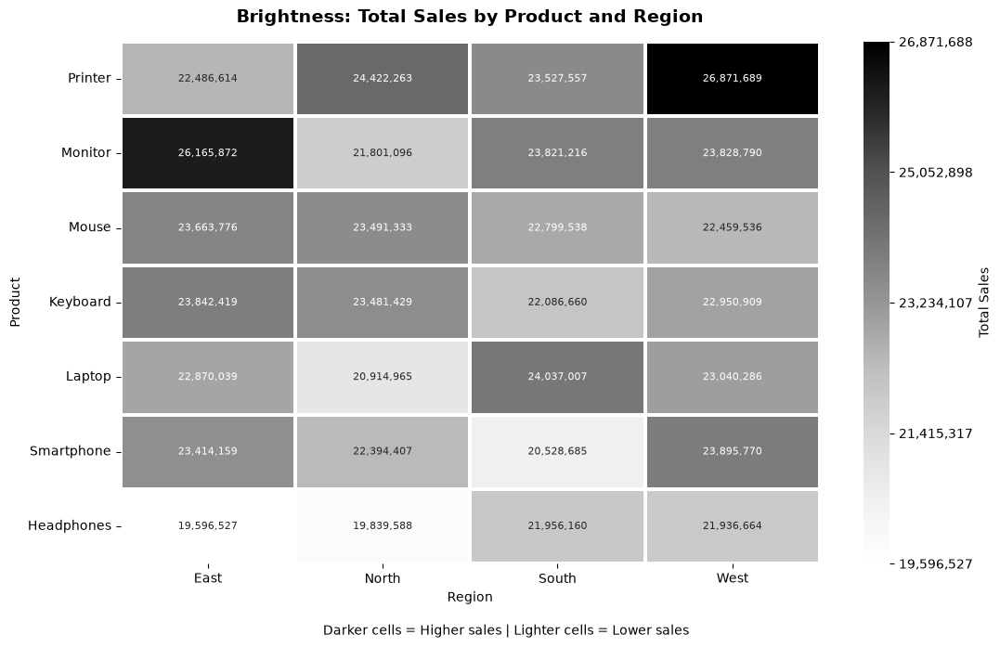

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load dataset
df = pd.read_csv("sales.csv")

# Calculate sales by product and region
sales = df.pivot_table(
    values="TotalAmount",
    index="Product",
    columns="Region",
    aggfunc="sum"
)

# Sort products by total sales
sales = sales.loc[
    sales.sum(axis=1).sort_values(ascending=False).index
]

# Format values with commas instead of scientific notation
labels = sales.apply(
    lambda col: col.map(lambda x: f"{x:,.0f}")
)

# Create heatmap
fig, ax = plt.subplots(figsize=(11, 7))

sns.heatmap(
    sales,
    annot=labels,
    fmt="",
    cmap="Greys",
    linewidths=1.5,
    linecolor="white",
    annot_kws={"fontsize": 8},
    cbar_kws={"label": "Total Sales"},
    ax=ax
)

# Format colorbar without scientific notation
cbar = ax.collections[0].colorbar
ticks = np.linspace(sales.min().min(), sales.max().max(), 5)

cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{int(v):,}" for v in ticks])
cbar.ax.yaxis.get_offset_text().set_visible(False)

# Labels and title
ax.set_title(
    "Brightness: Total Sales by Product and Region",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Region")
ax.set_ylabel("Product")

plt.figtext(
    0.5, 0.015,
    "Darker cells = Higher sales | Lighter cells = Lower sales",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save high-quality output
plt.savefig(
    "Experiment5_Brightness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

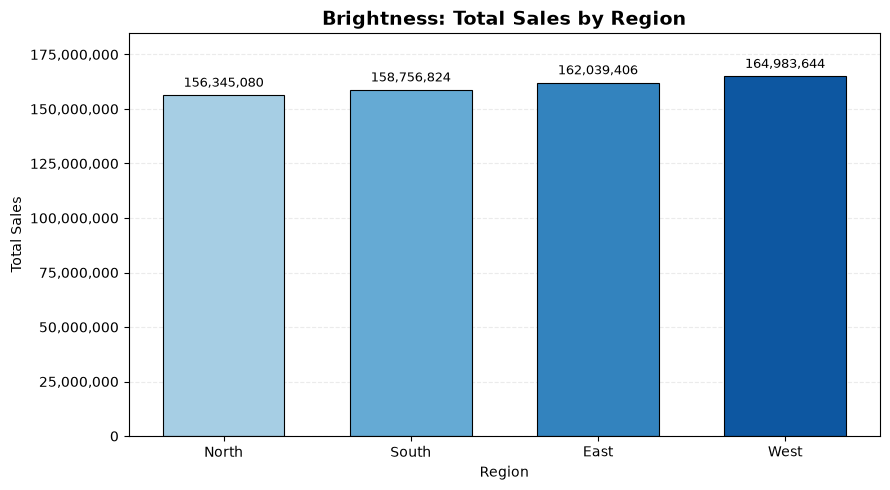

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# Load dataset
df = pd.read_csv("sales.csv")

# Calculate total sales by region
sales = df.groupby("Region")["TotalAmount"].sum().sort_values()

# Create shades of blue: lighter = lower sales, darker = higher sales
colors = plt.cm.Blues(np.linspace(0.35, 0.85, len(sales)))

# Create bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    sales.index,
    sales.values,
    color=colors,
    edgecolor="black",
    linewidth=0.8,
    width=0.65
)

# Display sales values above bars
for bar, value in zip(bars, sales.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + sales.max() * 0.015,
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Prevent scientific notation on Y-axis
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)
ax.yaxis.get_offset_text().set_visible(False)

ax.set_ylim(0, sales.max() * 1.12)
ax.set_xlabel("Region")
ax.set_ylabel("Total Sales")
ax.set_title(
    "Brightness: Total Sales by Region",
    fontsize=14,
    fontweight="bold"
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "Experiment5_Brightness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Load dataset
df = pd.read_csv("sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Calculate total sales for each date
daily = (
    df.groupby("Date", as_index=False)["TotalAmount"]
    .sum()
    .sort_values("Date")
    .reset_index(drop=True)
)

# Create graph
fig, ax = plt.subplots(figsize=(10, 5))

ax.set_xlim(daily["Date"].min(), daily["Date"].max())
ax.set_ylim(0, daily["TotalAmount"].max() * 1.15)

ax.set_xlabel("Date")
ax.set_ylabel("Total Sales")
ax.set_title(
    "Motion: Animated Sales Over Time",
    fontsize=13,
    fontweight="bold"
)

# Format date axis
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

# Animated line and moving point
line, = ax.plot([], [], "b-o", linewidth=1.8, markersize=3)

def update(frame):
    current = daily.iloc[:frame + 1]

    line.set_data(
        current["Date"],
        current["TotalAmount"]
    )

    return line,

# Create animation
animation = FuncAnimation(
    fig,
    update,
    frames=len(daily),
    interval=100,
    repeat=True,
    blit=False
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.close(fig)

# Display animation in Jupyter Notebook
display(HTML(animation.to_jshtml(fps=10)))

Animation size has reached 21008104 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Load dataset
df = pd.read_csv("sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Calculate monthly total sales
monthly = df.groupby(
    df["Date"].dt.to_period("M")
)["TotalAmount"].sum().reset_index()

monthly["Date"] = monthly["Date"].dt.to_timestamp()

# Create graph
fig, ax = plt.subplots(figsize=(10, 5))

ax.set_xlim(monthly["Date"].min(), monthly["Date"].max())
ax.set_ylim(0, monthly["TotalAmount"].max() * 1.15)

ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")
ax.set_title(
    "Motion: Animated Monthly Sales Over Time",
    fontsize=13,
    fontweight="bold"
)

# Format X-axis by month
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Animated line
line, = ax.plot(
    [], [],
    "b-o",
    linewidth=1.8,
    markersize=4
)

def update(frame):
    current = monthly.iloc[:frame + 1]

    line.set_data(
        current["Date"],
        current["TotalAmount"]
    )

    return line,

# Create animation
animation = FuncAnimation(
    fig,
    update,
    frames=len(monthly),
    interval=400,
    repeat=True,
    blit=False
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.close(fig)

# Display animation in Jupyter Notebook
display(HTML(animation.to_jshtml(fps=5)))